# 3. Cross-validation and model selection

A model can score well by memorizing training examples rather than learning patterns that generalize. In this lesson, we compare decision trees of different depths using cross-validation on training data only.

## Learning goals
- Describe how cross-validation estimates performance across several train/validation splits.
- Compare model complexity using training and validation scores.
- Select a model setting without repeatedly tuning against the test set.

**Important:** In lesson 2, we already looked at the test-set results. That means those examples have been seen during this learning exercise; do not treat them as an untouched final test for future performance claims. In a real project, keep a fresh test set until model selection is complete, or use nested cross-validation for an unbiased estimate after tuning.

## 1. Recreate the training split

We use the same fixed split as lesson 2 so the 30 examples reserved there are excluded from model selection. All comparisons below use only the 120 training examples.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training examples for model selection: {len(X_train)}")
print(f"Previously viewed test examples (not used below): {len(X_test)}")

Training examples for model selection: 120
Previously viewed test examples (not used below): 30


## 2. Compare tree depths with cross-validation

In 5-fold cross-validation, the training set is divided into five parts. Each model trains on four parts and validates on the remaining part, rotating which part is held out. We average the five validation scores. `StratifiedKFold` keeps the species proportions similar in every fold, and a fixed random state makes the folds reproducible.

A very deep tree can fit its training fold extremely well but perform less consistently on validation folds. We will compare depths 1 through 8 using accuracy and macro F1. Macro F1 gives each species equal weight.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for depth in range(1, 9):
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        return_train_score=True,
    )
    results.append(
        {
            "max_depth": depth,
            "train_accuracy": scores["train_accuracy"].mean(),
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_accuracy_std": scores["test_accuracy"].std(),
            "cv_macro_f1": scores["test_macro_f1"].mean(),
        }
    )

results_df = pd.DataFrame(results)
results_df.round(3)

,max_depth,train_accuracy,cv_accuracy,cv_accuracy_std,cv_macro_f1
0,1,0.667,0.667,0.000,0.556
1,2,0.967,0.942,0.020,0.941
2,3,0.979,0.958,0.026,0.958
3,4,0.994,0.942,0.020,0.941
4,5,0.998,0.950,0.017,0.950
5,6,1.000,0.950,0.017,0.950
6,7,1.000,0.950,0.017,0.950
7,8,1.000,0.950,0.017,0.950


The training score measures fit on examples each fold model learned from. The cross-validation score measures performance on that fold's held-out examples. A large gap can be a sign of overfitting. The standard deviation shows how much validation accuracy varied across folds; with a small dataset, fold-to-fold variation matters.

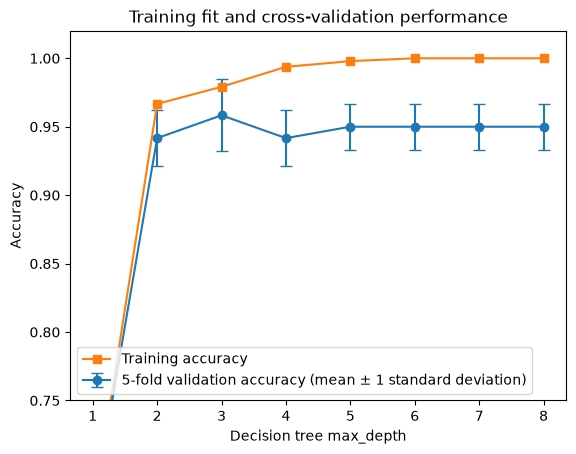

In [3]:
plt.errorbar(
    results_df["max_depth"],
    results_df["cv_accuracy"],
    yerr=results_df["cv_accuracy_std"],
    marker="o",
    capsize=4,
    label="5-fold validation accuracy (mean ± 1 standard deviation)",
)
plt.plot(results_df["max_depth"], results_df["train_accuracy"], marker="s", label="Training accuracy")
plt.xlabel("Decision tree max_depth")
plt.ylabel("Accuracy")
plt.title("Training fit and cross-validation performance")
plt.xticks(results_df["max_depth"])
plt.ylim(0.75, 1.02)
plt.legend()
plt.show()

## 3. Choose a candidate and refit it

We choose the depth with the highest mean cross-validation accuracy. If multiple depths tie, this rule chooses the shallower tree, favoring a simpler model. This is a learning example, not a guarantee that this setting is best for every dataset.

In [4]:
best_row = results_df.sort_values(
    ["cv_accuracy", "max_depth"], ascending=[False, True]
).iloc[0]
selected_depth = int(best_row["max_depth"])

selected_model = DecisionTreeClassifier(max_depth=selected_depth, random_state=42)
selected_model.fit(X_train, y_train)

print(f"Selected max_depth: {selected_depth}")
print(f"Mean 5-fold validation accuracy: {best_row['cv_accuracy']:.1%}")
print(f"Mean 5-fold validation macro F1: {best_row['cv_macro_f1']:.1%}")
print("\nThis candidate is now fitted on the full training split.")

Selected max_depth: 3
Mean 5-fold validation accuracy: 95.8%
Mean 5-fold validation macro F1: 95.8%

This candidate is now fitted on the full training split.


We intentionally do not score this selected model on the previously viewed test examples. Model selection used cross-validation on the training split; for an independent final estimate after this exercise, use a fresh test set or nested cross-validation.

## Your notes

1. Which tree depth had the highest mean validation accuracy? Which depth would you choose if two tied?
2. At what depth, if any, did training accuracy keep rising while validation performance stopped improving?
3. Why is cross-validation useful when the dataset is small?
4. Why should we not keep checking the same test set while changing model settings?

## What comes next

Next, we will move the reusable training workflow into Python modules, add a small automated test, and save the selected model so it can be used by an API.